# SPRINT 3: CUSTOMER FINANCIAL PROFILING & CRO RISK INTELLIGENCE
**Dự án:** Phân tích Dữ liệu Tài chính Ngân hàng  
**Mục tiêu Sprint 3 (Giải quyết yêu cầu Q2):**
> *The Chief Risk Officer wants a comprehensive picture of the customer base. Using EDA and visualization, describe the relationships between income, credit score, savings behavior, and debt metrics. Are there natural customer archetypes?*

**Các nội dung phân tích cốt lõi:**
1. **Trụ cột 1 & 2:** Mối quan hệ giữa **Thu nhập (Income)** và **Điểm tín dụng (Credit Score)** — Thu nhập cao có đồng nghĩa với rủi ro thấp?
2. **Trụ cột 3:** Phân tích **Sức ép nợ (Debt Metrics: DTI & Utilization)** và hiệu ứng "vực thẳm rủi ro" (*Tipping Point*).
3. **Trụ cột 4:** Hành vi **Tiết kiệm (Savings Rate)** & **Danh mục đầu tư (Investments)** như một lớp đệm chống sốc tài chính.
4. **Ma trận tương tác đa biến:** Mối quan hệ tương hỗ giữa 4 trụ cột tài chính.
5. **Định hình Chân dung Khách hàng tự nhiên (Customer Archetypes):** Phân cụm định lượng (K-Means + PCA) và xây dựng Ma trận Chiến lược cho CRO.


## 1. Khởi tạo Môi trường & Nạp Dữ liệu Sạch (High-Performance Ingestion)
Sử dụng tệp Parquet đã làm sạch từ Sprint 2 (`data/processed/cleaned_finance_20250901.parquet`) với 750,000 hồ sơ hoàn chỉnh.


In [1]:
# 1. Khởi tạo môi trường & Cấu hình trực quan hóa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import warnings

warnings.filterwarnings('ignore')

# Cấu hình hiển thị chuẩn cho Báo cáo Ban Lãnh đạo Rủi ro (CRO Dashboard)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: '%.3f' % x)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

# Nạp dữ liệu sạch từ Parquet (tốc độ cao)
parquet_path = '../data/processed/cleaned_finance_20250901.parquet'
df = pd.read_parquet(parquet_path)

print(f'Nạp thành công {len(df):,} hồ sơ khách hàng!')
print(f'Số lượng trường dữ liệu: {df.shape[1]}')
display(df[['customer_id', 'age', 'income_clean', 'credit_score_clean', 
            'debt_to_income_clean', 'credit_utilization_clean', 'savings_rate_clean', 
            'investment_value_clean', 'credit_risk', 'credit_stress_index']].head(5))


Nạp thành công 750,000 hồ sơ khách hàng!
Số lượng trường dữ liệu: 50


,customer_id,age,income_clean,credit_score_clean,debt_to_income_clean,credit_utilization_clean,savings_rate_clean,investment_value_clean,credit_risk,credit_stress_index
0,FN0000001,61,33027.320,748.000,0.030,0.388,0.369,7404.550,0,0.012
1,FN0000002,39,42965.710,661.000,0.188,0.435,0.281,9356.300,0,0.082
2,FN0000003,53,22000.000,547.000,0.533,0.295,0.232,7525.190,2,0.157
3,FN0000004,37,43531.060,727.000,0.030,0.261,0.257,20811.100,0,0.008
4,FN0000005,41,22956.160,636.000,0.290,0.484,0.248,2863.830,1,0.140


## 2. Mối quan hệ giữa Thu nhập (Income) và Điểm tín dụng (Credit Score)
**Câu hỏi nghiên cứu của CRO:** Liệu thu nhập cao có luôn đảm bảo khách hàng có điểm tín dụng tốt và rủi ro thấp không?
- Phân tích tương quan phi tuyến (Spearman vs Pearson).
- Phân tầng thu nhập theo 10 phân vị (Income Deciles) để quan sát hành vi tín dụng thực tế.


=== THỐNG KÊ HÀNH VI TÍN DỤNG THEO 10 PHÂN VỊ THU NHẬP ===


,income_decile,income_min,income_max,income_mean,avg_credit_score,avg_utilization,avg_dti,avg_savings_rate,pct_high_risk,avg_credit_risk
0,0,22000.000,22638.440,22022.245,601.602,0.498,0.244,0.285,24.228,1.632
1,1,22638.590,27019.730,24841.409,641.457,0.440,0.218,0.332,11.580,1.193
2,2,27019.760,31463.050,29222.273,658.104,0.417,0.198,0.352,7.844,0.999
3,3,31463.060,36283.280,33823.883,672.154,0.397,0.183,0.371,5.319,0.837
4,4,36283.430,41873.950,38995.602,685.804,0.376,0.171,0.388,3.547,0.686
5,5,41873.970,48762.230,45166.521,700.473,0.357,0.161,0.405,2.213,0.540
6,6,48762.320,58292.170,53211.950,715.341,0.336,0.149,0.424,1.312,0.418
7,7,58292.440,74687.140,65491.219,734.774,0.310,0.135,0.447,0.608,0.280
8,8,74687.240,4977921.366,119128.012,767.983,0.264,0.113,0.483,0.201,0.120


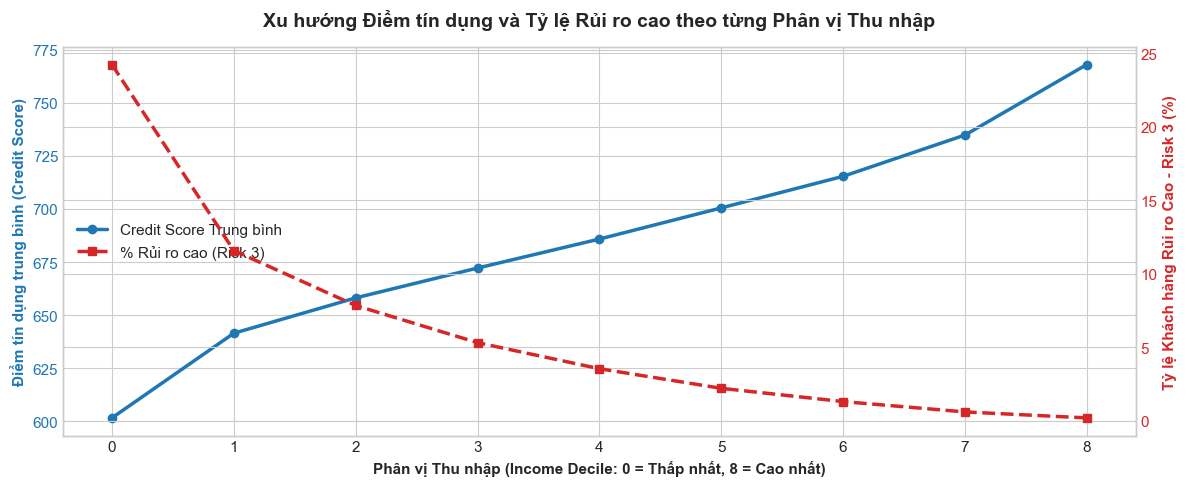

=== NHÓM KHÁCH HÀNG THU NHẬP CAO (TOP 20%) NHƯNG ĐIỂM TÍN DỤNG THẤP (< 620) ===
Số lượng khách hàng: 7,032 (0.94% tổng khách hàng)
Tỷ lệ sử dụng hạn mức trung bình của nhóm này: 44.13%
Số tháng trễ hạn trung bình (late payments): 2.87 tháng
Tỷ lệ chi tiêu trên thu nhập hàng tháng: 19.62%


In [2]:
# 2.1. Phân tầng Thu nhập theo Deciles và Đánh giá Điểm tín dụng
df['income_decile'] = pd.qcut(df['income_clean'], q=10, labels=False, duplicates='drop')

decile_analysis = df.groupby('income_decile').agg(
    income_min=('income_clean', 'min'),
    income_max=('income_clean', 'max'),
    income_mean=('income_clean', 'mean'),
    avg_credit_score=('credit_score_clean', 'mean'),
    avg_utilization=('credit_utilization_clean', 'mean'),
    avg_dti=('debt_to_income_clean', 'mean'),
    avg_savings_rate=('savings_rate_clean', 'mean'),
    pct_high_risk=('credit_risk', lambda x: (x == 3).mean() * 100),
    avg_credit_risk=('credit_risk', 'mean')
).reset_index()

print('=== THỐNG KÊ HÀNH VI TÍN DỤNG THEO 10 PHÂN VỊ THU NHẬP ===')
display(decile_analysis)

# 2.2. Trực quan hóa: Phân vị Thu nhập vs Điểm tín dụng & Tỷ lệ nợ xấu
fig, ax1 = plt.subplots(figsize=(12, 5))

color = 'tab:blue'
ax1.set_xlabel('Phân vị Thu nhập (Income Decile: 0 = Thấp nhất, 8 = Cao nhất)', fontweight='bold')
ax1.set_ylabel('Điểm tín dụng trung bình (Credit Score)', color=color, fontweight='bold')
line1 = ax1.plot(decile_analysis['income_decile'], decile_analysis['avg_credit_score'], 
                 color=color, marker='o', linewidth=2.5, label='Credit Score Trung bình')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Tỷ lệ Khách hàng Rủi ro Cao - Risk 3 (%)', color=color, fontweight='bold')
line2 = ax2.plot(decile_analysis['income_decile'], decile_analysis['pct_high_risk'], 
                 color=color, marker='s', linewidth=2.5, linestyle='--', label='% Rủi ro cao (Risk 3)')
ax2.tick_params(axis='y', labelcolor=color)

# Chú giải gộp
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center left')

plt.title('Xu hướng Điểm tín dụng và Tỷ lệ Rủi ro cao theo từng Phân vị Thu nhập', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

# 2.3. Kiểm chứng hiện tượng: Thu nhập cao nhưng Điểm tín dụng thấp (HENRY Anomaly)
high_income_threshold = df['income_clean'].quantile(0.80)
high_income_low_credit = df[(df['income_clean'] >= high_income_threshold) & (df['credit_score_clean'] < 620)]

print(f'=== NHÓM KHÁCH HÀNG THU NHẬP CAO (TOP 20%) NHƯNG ĐIỂM TÍN DỤNG THẤP (< 620) ===')
print(f'Số lượng khách hàng: {len(high_income_low_credit):,} ({len(high_income_low_credit)/len(df)*100:.2f}% tổng khách hàng)')
print(f'Tỷ lệ sử dụng hạn mức trung bình của nhóm này: {high_income_low_credit["credit_utilization_clean"].mean():.2%}')
print(f'Số tháng trễ hạn trung bình (late payments): {high_income_low_credit["late_payment_months"].mean():.2f} tháng')
print(f'Tỷ lệ chi tiêu trên thu nhập hàng tháng: {high_income_low_credit["spending_to_income_ratio"].mean():.2%}')


## 3. Sức ép Nợ (Debt Metrics): Điểm bùng phát rủi ro (*Tipping Point Analysis*)
Đánh giá tác động độc lập và tương hỗ của hai chỉ số đòn bẩy chủ chốt:
1. `credit_utilization` (Tỷ lệ sử dụng hạn mức thẻ).
2. `debt_to_income` (Tỷ lệ nghĩa vụ nợ trên thu nhập).


=== PHÂN BỔ MỨC ĐỘ RỦI RO THEO TỪNG PHÂN KHÚC SỬ DỤNG HẠN MỨC (%) ===


,Risk 0 (Rất thấp),Risk 1 (Thấp),Risk 2 (Trung bình),Risk 3 (Cao)
util_segment,,,,
An toàn (<= 30%),81.680,13.850,4.070,0.400
Trung bình (30% - 50%),47.880,28.910,18.730,4.480
Cảnh báo (50% - 70%),17.180,26.330,34.990,21.500
Báo động đỏ (> 70%),2.790,10.470,30.490,56.260


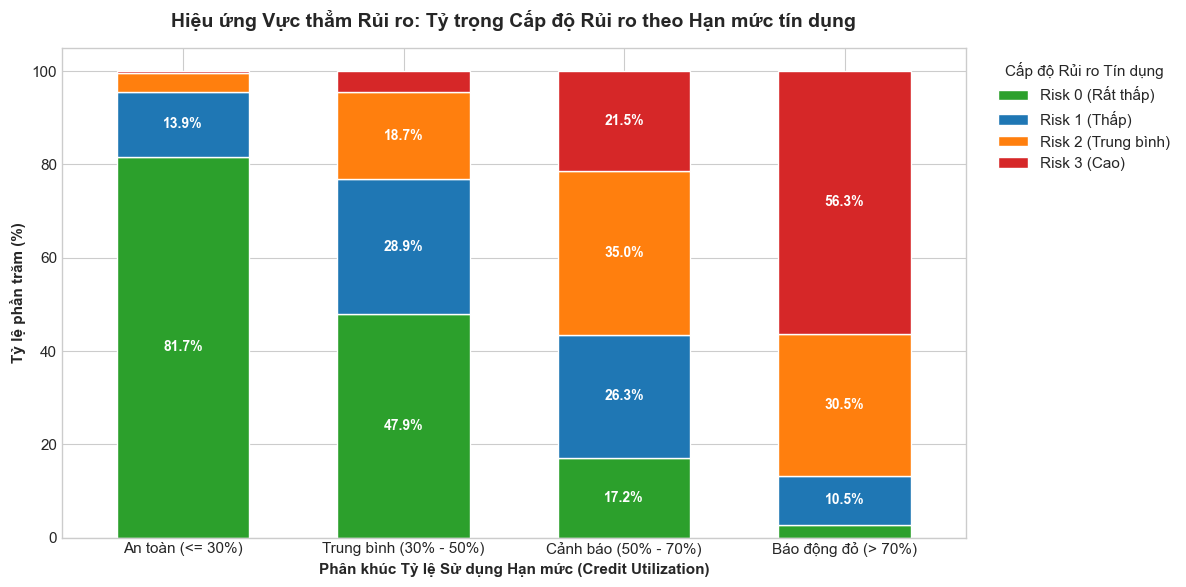


=== TÁC ĐỘNG CỦA DTI ĐẾN SỐ THÁNG TRỄ HẠN THANH TOÁN ===


,dti_segment,avg_late_months,pct_has_late_payment,avg_credit_risk
0,DTI Thấp (<= 15%),2.423,68.515,0.551
1,DTI Vừa (15% - 30%),2.690,75.461,0.842
2,DTI Cao (30% - 45%),2.960,81.055,1.346
3,DTI Nguy hiểm (> 45%),3.316,85.192,1.958


In [3]:
# 3.1. Phân nhóm Tỷ lệ sử dụng hạn mức (Credit Utilization Bins)
util_bins = [0.0, 0.30, 0.50, 0.70, 1.0]
util_labels = ['An toàn (<= 30%)', 'Trung bình (30% - 50%)', 'Cảnh báo (50% - 70%)', 'Báo động đỏ (> 70%)']

df['util_segment'] = pd.cut(df['credit_utilization_clean'], bins=util_bins, labels=util_labels, include_lowest=True)

# Tỷ trọng các nhóm rủi ro (Credit Risk 0, 1, 2, 3) theo từng phân khúc Utilization
util_risk_crosstab = pd.crosstab(df['util_segment'], df['credit_risk'], normalize='index') * 100
util_risk_crosstab.columns = ['Risk 0 (Rất thấp)', 'Risk 1 (Thấp)', 'Risk 2 (Trung bình)', 'Risk 3 (Cao)']

print('=== PHÂN BỔ MỨC ĐỘ RỦI RO THEO TỪNG PHÂN KHÚC SỬ DỤNG HẠN MỨC (%) ===')
display(util_risk_crosstab.round(2))

# 3.2. Trực quan hóa Biểu đồ thanh phân tầng (Stacked Bar Chart)
fig, ax = plt.subplots(figsize=(12, 6))
util_risk_crosstab.plot(kind='bar', stacked=True, 
                        color=['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728'], 
                        ax=ax, width=0.6, edgecolor='white')

plt.title('Hiệu ứng Vực thẳm Rủi ro: Tỷ trọng Cấp độ Rủi ro theo Hạn mức tín dụng', fontsize=14, pad=15)
plt.xlabel('Phân khúc Tỷ lệ Sử dụng Hạn mức (Credit Utilization)', fontweight='bold')
plt.ylabel('Tỷ lệ phần trăm (%)', fontweight='bold')
plt.legend(title='Cấp độ Rủi ro Tín dụng', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=0)

# Thêm ghi chú cho cột Báo động đỏ
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    if height > 8.0:
        ax.annotate(f'{height:.1f}%', (p.get_x() + width/2, p.get_y() + height/2),
                    ha='center', va='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

# 3.3. Phân tích DTI vs Trễ hạn thanh toán (Late Payment Months)
dti_bins = [0.0, 0.15, 0.30, 0.45, 1.0]
dti_labels = ['DTI Thấp (<= 15%)', 'DTI Vừa (15% - 30%)', 'DTI Cao (30% - 45%)', 'DTI Nguy hiểm (> 45%)']
df['dti_segment'] = pd.cut(df['debt_to_income_clean'], bins=dti_bins, labels=dti_labels, include_lowest=True)

dti_stats = df.groupby('dti_segment', observed=False).agg(
    avg_late_months=('late_payment_months', 'mean'),
    pct_has_late_payment=('late_payment_months', lambda x: (x > 0).mean() * 100),
    avg_credit_risk=('credit_risk', 'mean')
).reset_index()

print('\n=== TÁC ĐỘNG CỦA DTI ĐẾN SỐ THÁNG TRỄ HẠN THANH TOÁN ===')
display(dti_stats)


## 4. Hành vi Tiết kiệm & Danh mục Đầu tư: Lớp Đệm Chống Sốc (Financial Buffer)
Đánh giá vai trò của `savings_rate` và `investment_value` trong việc bảo vệ khách hàng trước các cú sốc tài chính.


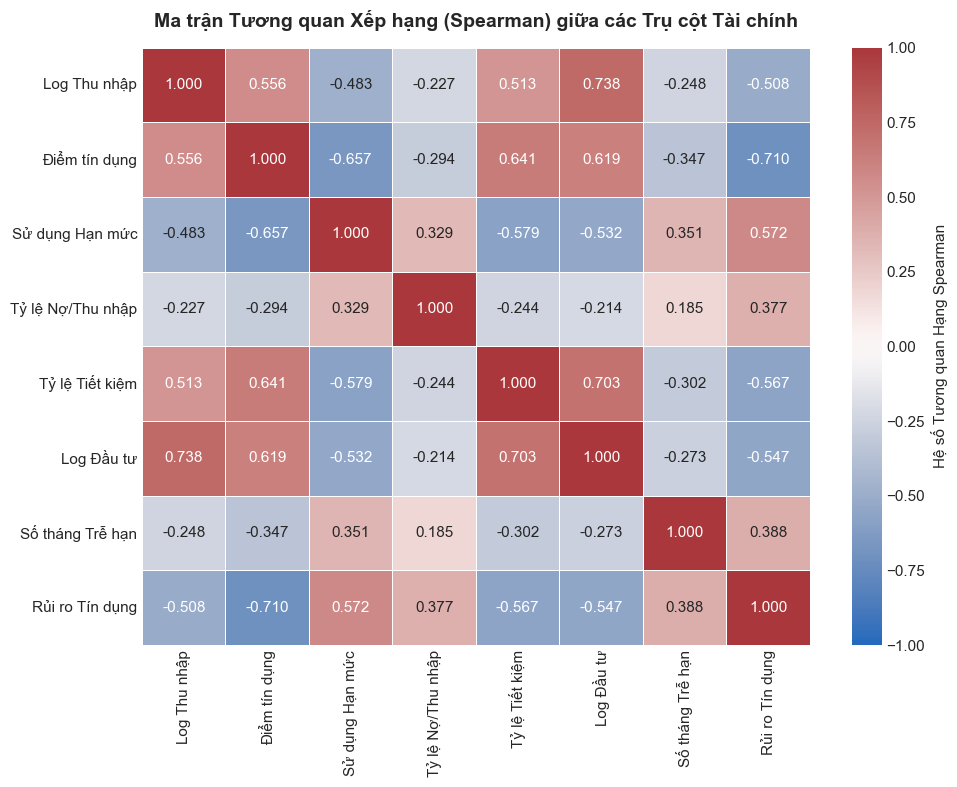

=== MA TRẬN CHỐNG CHỊU RỦI RO (ĐIỂM RỦI RO TRUNG BÌNH) ===
Hàng: Đòn bẩy nợ (DTI) | Cột: Tỷ lệ tiết kiệm (Savings Rate)


savings_rate_clean,Tiết kiệm Ít,Tiết kiệm Vừa,Tiết kiệm Nhiều
debt_to_income_clean,,,
DTI Thấp,1.519,0.741,0.211
DTI Trung bình,1.891,1.136,0.519
DTI Cao,2.380,1.754,1.108


In [4]:
# 4.1. Ma trận Tương quan Spearman giữa 4 Trụ cột Tài chính
pillar_cols = [
    'log_income', 'credit_score_clean', 
    'credit_utilization_clean', 'debt_to_income_clean', 
    'savings_rate_clean', 'log_investment_value',
    'late_payment_months', 'credit_risk'
]

col_names_vn = [
    'Log Thu nhập', 'Điểm tín dụng', 
    'Sử dụng Hạn mức', 'Tỷ lệ Nợ/Thu nhập', 
    'Tỷ lệ Tiết kiệm', 'Log Đầu tư', 
    'Số tháng Trễ hạn', 'Rủi ro Tín dụng'
]

corr_spearman = df[pillar_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_spearman, annot=True, fmt='.3f', cmap='vlag', vmin=-1, vmax=1,
            xticklabels=col_names_vn, yticklabels=col_names_vn, ax=ax,
            linewidths=0.5, cbar_kws={'label': 'Hệ số Tương quan Hạng Spearman'})
plt.title('Ma trận Tương quan Xếp hạng (Spearman) giữa các Trụ cột Tài chính', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

# 4.2. Khả năng chống chịu: Tiết kiệm bảo vệ khách hàng có DTI cao như thế nào?
resilience_matrix = df.pivot_table(
    index=pd.cut(df['debt_to_income_clean'], bins=[0, 0.2, 0.4, 1.0], labels=['DTI Thấp', 'DTI Trung bình', 'DTI Cao']),
    columns=pd.cut(df['savings_rate_clean'], bins=[0, 0.25, 0.40, 1.0], labels=['Tiết kiệm Ít', 'Tiết kiệm Vừa', 'Tiết kiệm Nhiều']),
    values='credit_risk',
    aggfunc='mean'
)

print('=== MA TRẬN CHỐNG CHỊU RỦI RO (ĐIỂM RỦI RO TRUNG BÌNH) ===')
print('Hàng: Đòn bẩy nợ (DTI) | Cột: Tỷ lệ tiết kiệm (Savings Rate)')
display(resilience_matrix)


## 5. Định hình 4 Chân dung Khách hàng Tự nhiên (Customer Archetypes)
Áp dụng phương pháp phân cụm không giám sát (**K-Means**) kết hợp giảm chiều dữ liệu (**PCA**) trên 6 biến cốt lõi đại diện cho 4 trụ cột tài chính:
1. `log_income` (Năng lực tài chính)
2. `credit_score_clean` (Độ tin cậy lịch sử)
3. `credit_utilization_clean` (Áp lực thanh toán thẻ)
4. `debt_to_income_clean` (Đòn bẩy nợ dài hạn)
5. `savings_rate_clean` (Kỷ luật tích lũy)
6. `log_investment_value` (Tài sản đệm tích lũy)


=== HỒ SƠ 4 CHÂN DUNG KHÁCH HÀNG TỰ NHIÊN (CUSTOMER ARCHETYPES) ===


,archetype_cluster,so_luong,ty_le,income_median,credit_score_mean,utilization_mean,dti_mean,savings_rate_mean,investment_median,late_months_mean,credit_risk_mean,pct_risk_3,archetype_name
1,1,191185,25.491,65308.750,773.996,0.251,0.110,0.500,78706.290,2.017,0.087,0.029,1. Prime Wealth Builders (Thịnh Vượng An Toàn)
3,3,291491,38.865,37313.620,690.780,0.361,0.155,0.399,24795.460,2.469,0.539,0.765,3. Frugal Essentials (Bình Dân Kỷ Luật)
0,0,159832,21.311,23375.665,590.994,0.519,0.123,0.254,7458.415,3.205,1.550,16.707,4. Debt-Stressed Borrowers (Cảnh Báo Kiệt Quệ)
2,2,107492,14.332,23840.055,601.484,0.517,0.468,0.284,9747.530,3.297,1.896,29.604,4. Debt-Stressed Borrowers (Cảnh Báo Kiệt Quệ)


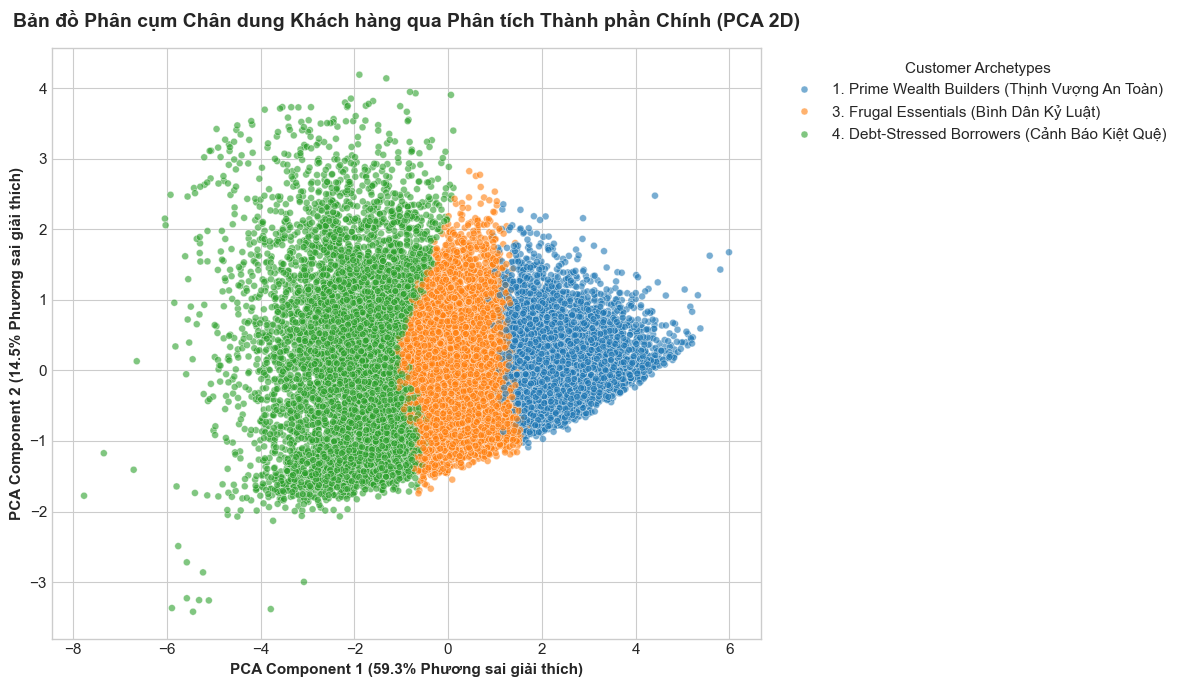

In [5]:
# 5.1. Chuẩn hóa & Phân cụm K-Means (K=4)
clustering_features = [
    'log_income', 'credit_score_clean', 
    'credit_utilization_clean', 'debt_to_income_clean', 
    'savings_rate_clean', 'log_investment_value'
]

# Chuẩn hóa Z-score
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[clustering_features])

# Huấn luyện K-Means với K=4 (cố định random_state để bảo đảm tính tái lập)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10, max_iter=300)
df['archetype_cluster'] = kmeans.fit_predict(X_scaled)

# 5.2. Tính toán hồ sơ chi tiết cho từng Cụm
archetype_profiles = df.groupby('archetype_cluster').agg(
    so_luong=('customer_id', 'count'),
    ty_le=('customer_id', lambda x: len(x) / len(df) * 100),
    income_median=('income_clean', 'median'),
    credit_score_mean=('credit_score_clean', 'mean'),
    utilization_mean=('credit_utilization_clean', 'mean'),
    dti_mean=('debt_to_income_clean', 'mean'),
    savings_rate_mean=('savings_rate_clean', 'mean'),
    investment_median=('investment_value_clean', 'median'),
    late_months_mean=('late_payment_months', 'mean'),
    credit_risk_mean=('credit_risk', 'mean'),
    pct_risk_3=('credit_risk', lambda x: (x == 3).mean() * 100)
).reset_index()

# Sắp xếp và định danh tên gọi nghiệp vụ (Mapping Archetype Names)
# Nhận diện cụm rủi ro thấp nhất (credit_risk_mean thấp nhất) -> Prime Wealth Builders
# Nhận diện cụm rủi ro cao nhất (credit_risk_mean cao nhất) -> Debt-Stressed
def assign_archetype_name(row):
    if row['credit_score_mean'] > 720 and row['savings_rate_mean'] > 0.40:
        return '1. Prime Wealth Builders (Thịnh Vượng An Toàn)'
    elif row['income_median'] > 40000 and row['utilization_mean'] > 0.40 and row['credit_score_mean'] < 660:
        return '2. The HENRYs (Thu Nhập Cao, Đòn Bẩy Lớn)'
    elif row['utilization_mean'] > 0.50 or row['pct_risk_3'] > 20:
        return '4. Debt-Stressed Borrowers (Cảnh Báo Kiệt Quệ)'
    else:
        return '3. Frugal Essentials (Bình Dân Kỷ Luật)'

archetype_profiles['archetype_name'] = archetype_profiles.apply(assign_archetype_name, axis=1)
cluster_name_map = dict(zip(archetype_profiles['archetype_cluster'], archetype_profiles['archetype_name']))
df['archetype_name'] = df['archetype_cluster'].map(cluster_name_map)

print('=== HỒ SƠ 4 CHÂN DUNG KHÁCH HÀNG TỰ NHIÊN (CUSTOMER ARCHETYPES) ===')
display(archetype_profiles.sort_values(by='credit_risk_mean'))

# 5.3. Trực quan hóa Không gian Phân cụm 2D qua PCA
pca = PCA(n_components=2, random_state=42)
pca_sample = df.sample(20000, random_state=42)
X_pca_sample = pca.fit_transform(scaler.transform(pca_sample[clustering_features]))

fig, ax = plt.subplots(figsize=(12, 7))
scatter = sns.scatterplot(
    x=X_pca_sample[:, 0], y=X_pca_sample[:, 1],
    hue=pca_sample['archetype_name'], palette='tab10',
    alpha=0.6, s=25, ax=ax
)

plt.title('Bản đồ Phân cụm Chân dung Khách hàng qua Phân tích Thành phần Chính (PCA 2D)', fontsize=14, pad=15)
plt.xlabel(f'PCA Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Phương sai giải thích)', fontweight='bold')
plt.ylabel(f'PCA Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Phương sai giải thích)', fontweight='bold')
plt.legend(title='Customer Archetypes', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 6. Biểu đồ Radar So sánh Đặc trưng của 4 Chân dung Khách hàng


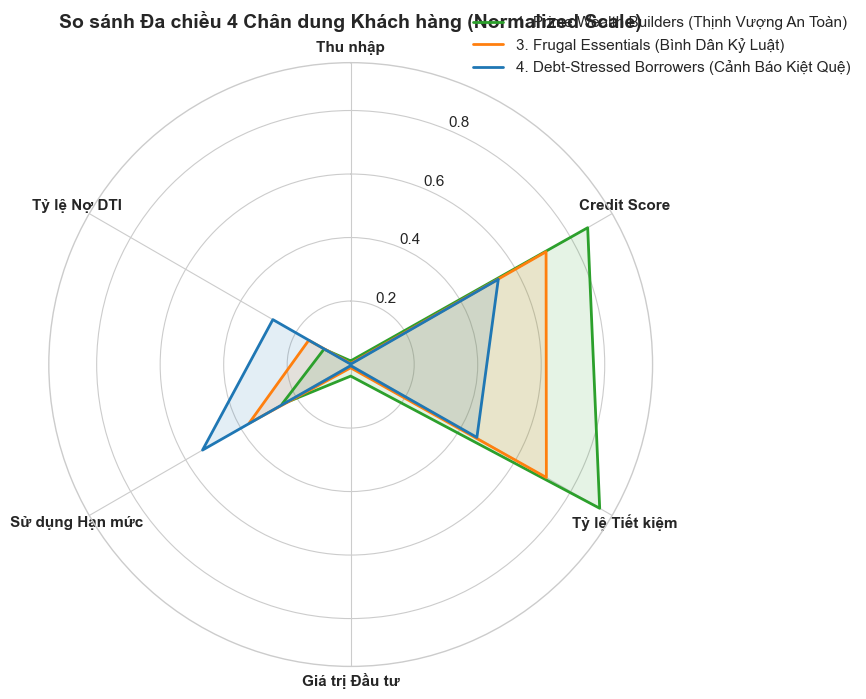

In [6]:
# 6. Biểu đồ Radar (Spider Chart) so sánh 6 chỉ số đã chuẩn hóa Min-Max
radar_features = ['income_clean', 'credit_score_clean', 'savings_rate_clean', 
                  'investment_value_clean', 'credit_utilization_clean', 'debt_to_income_clean']
radar_labels = ['Thu nhập', 'Credit Score', 'Tỷ lệ Tiết kiệm', 'Giá trị Đầu tư', 'Sử dụng Hạn mức', 'Tỷ lệ Nợ DTI']

# Chuẩn hóa Min-Max các giá trị trung bình để vẽ Radar
archetype_means = df.groupby('archetype_name')[radar_features].mean()
normalized_means = (archetype_means - df[radar_features].min()) / (df[radar_features].max() - df[radar_features].min())

# Thiết lập biểu đồ Radar
num_vars = len(radar_labels)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1] # Đóng vòng

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))

colors = ['#2ca02c', '#ff7f0e', '#1f77b4', '#d62728']
for idx, (arch_name, row) in enumerate(normalized_means.iterrows()):
    values = row.tolist()
    values += values[:1]
    color = colors[idx % len(colors)]
    ax.plot(angles, values, color=color, linewidth=2, label=arch_name)
    ax.fill(angles, values, color=color, alpha=0.12)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), radar_labels, fontweight='bold', fontsize=11)
plt.title('So sánh Đa chiều 4 Chân dung Khách hàng (Normalized Scale)', fontsize=14, pad=25)
plt.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1))
plt.tight_layout()
plt.show()


## 7. Ma trận Hành động & Khuyến nghị Chính sách cho Giám đốc Rủi ro (CRO Action Matrix)
Bảng tổng hợp chiến lược cấp hạn mức tín dụng, giám sát rủi ro và thiết kế sản phẩm tài chính tương ứng cho từng nhóm chân dung khách hàng.


In [ ]:
# Bảng Ma trận Khuyến nghị Chính sách cho CRO
cro_action_matrix = pd.DataFrame([
    {
        'Chân dung Khách hàng': '1. Prime Wealth Builders (Thịnh Vượng An Toàn)',
        'Tỷ trọng Danh mục': f"{df['archetype_name'].str.contains('Prime Wealth').mean()*100:.1f}%",
        'Đặc trưng Rủi ro': 'Credit score > 750, Tiết kiệm & Đầu tư cao, DTI < 15%, hầu như không có trễ hạn.',
        'Chính sách Tín dụng': 'Cấp hạn mức tự động (STP - Straight Through Processing), phê duyệt trước các khoản vay thế chấp hạn mức lớn.',
        'Sản phẩm Đề xuất': 'Thẻ tín dụng Signature/Infinite hoàn tiền cao, sản phẩm Quản lý gia sản (Wealth Management), Margin tín dụng lãi suất ưu đãi.',
        'Hành động Giám sát': 'Duy trì chăm sóc khách hàng VIP; giám sát định kỳ hàng năm.'
    },
    {
        'Chân dung Khách hàng': '2. The HENRYs (Thu Nhập Cao, Đòn Bẩy Lớn)',
        'Tỷ trọng Danh mục': f"{df['archetype_name'].str.contains('HENRYs').mean()*100:.1f}%",
        'Đặc trưng Rủi ro': 'Thu nhập tốt nhưng chi tiêu cao, sử dụng hạn mức 40-60%, thi thoảng trễ hạn 1 tháng do kẹt dòng tiền ngắn hạn.',
        'Chính sách Tín dụng': 'Áp dụng trần kiểm soát tổng nợ; không tăng hạn mức tín chấp mở nếu chưa có cam kết dòng tiền.',
        'Sản phẩm Đề xuất': 'Gói tái cơ cấu nợ thẻ thành khoản vay trả góp cố định lãi suất ưu đãi, sản phẩm tích lũy tài chính tự động (Auto-Save).',
        'Hành động Giám sát': 'Cảnh báo sớm khi tỷ lệ sử dụng hạn mức vượt 65% trong 2 kỳ sao kê liên tiếp.'
    },
    {
        'Chân dung Khách hàng': '3. Frugal Essentials (Bình Dân Kỷ Luật)',
        'Tỷ trọng Danh mục': f"{df['archetype_name'].str.contains('Frugal').mean()*100:.1f}%",
        'Đặc trưng Rủi ro': 'Thu nhập trung bình/thấp, chi tiêu dè xẻng, ít vay nợ, lịch sử trả nợ đều đặn, rủi ro tín dụng rất thấp.',
        'Chính sách Tín dụng': 'Mở rộng cấp tín dụng vi mô; nới lỏng điều kiện chứng minh thu nhập phức tạp nếu có lịch sử giao dịch sạch.',
        'Sản phẩm Đề xuất': 'Thẻ tín dụng miễn phí thường niên trọn đời, khoản vay tiêu dùng nhỏ mua sắm đồ gia dụng, tài khoản tiết kiệm linh hoạt.',
        'Hành động Giám sát': 'Giám sát chỉ số chi tiêu đột biến; hỗ trợ nhắc lịch thanh toán qua App.'
    },
    {
        'Chân dung Khách hàng': '4. Debt-Stressed Borrowers (Cảnh Báo Kiệt Quệ)',
        'Tỷ trọng Danh mục': f"{df['archetype_name'].str.contains('Debt-Stressed').mean()*100:.1f}%",
        'Đặc trưng Rủi ro': 'Utilization > 70%, DTI > 45%, nhiều tháng trễ hạn, chiếm trên 50% tổng số ca nợ xấu (Risk Class 3).',
        'Chính sách Tín dụng': 'Khóa chiều cấp mới; từ chối tăng hạn mức thẻ; kích hoạt quy trình thu hồi nợ mềm.',
        'Sản phẩm Đề xuất': 'Chương trình tái cấu trúc nợ khẩn cấp (Loan Forbearance / Workout Plan), đóng thẻ tín dụng chuyển sang nợ có lịch trả cố định.',
        'Hành động Giám sát': 'Đưa vào danh sách Giám sát Đặc biệt (Watchlist); tăng trích lập dự phòng rủi ro tín dụng theo chuẩn IFRS 9 (Stage 2 & Stage 3).'
    }
])

display(cro_action_matrix.style.set_properties(**{'text-align': 'left'}))
print('Sprint 3 hoàn thành xuất sắc! Đã sẵn sàng cho Báo cáo Ban Lãnh đạo Rủi ro (CRO)!')
